In [2]:
import pandas as pd 
import numpy as np 

In [3]:
df=pd.read_csv("car_prices.csv")
df.head()

,car_id,mileage,selling_price
0,A001,126958,9734
1,A002,151867,8775
2,A003,136932,3928
3,A004,108694,12454
4,A005,124879,6634


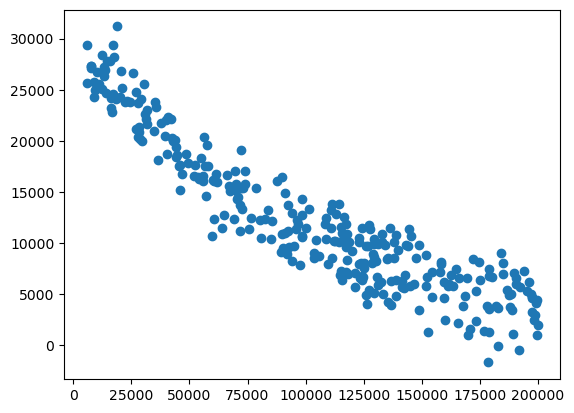

In [4]:
from matplotlib import pyplot as plt

plt.scatter(df['mileage'],df['selling_price'])

In [5]:
from sklearn.model_selection import train_test_split

X=df[['mileage']]
y=df['selling_price']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
X.shape,X_test.shape

((300, 1), (60, 1))

In [7]:
from sklearn.preprocessing import PolynomialFeatures 

poly=PolynomialFeatures(degree=2)
poly.fit_transform(np.array([[1],[2],[3],[4]]))

array([[ 1.,  1.,  1.],
       [ 1.,  2.,  4.],
       [ 1.,  3.,  9.],
       [ 1.,  4., 16.]])

In [8]:
X_train_poly= poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [9]:
X_train[:5]

,mileage
232,111081
59,129358
6,59886
185,145546
173,151779


In [11]:
X_train_poly[:5]

array([[1.00000000e+00, 1.11081000e+05, 1.23389886e+10],
       [1.00000000e+00, 1.29358000e+05, 1.67334922e+10],
       [1.00000000e+00, 5.98860000e+04, 3.58633300e+09],
       [1.00000000e+00, 1.45546000e+05, 2.11836381e+10],
       [1.00000000e+00, 1.51779000e+05, 2.30368648e+10]])

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error

model=LinearRegression()
model.fit(X_train_poly,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
y_pred=model.predict(X_test_poly)


In [19]:
mse=mean_squared_error(y_test,y_pred)
mse

4823730.839847335

In [21]:
r2=r2_score(y_test,y_pred)
r2

0.915725557514736

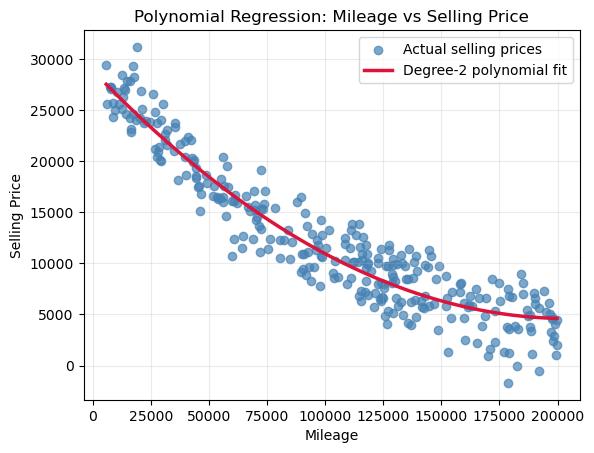

In [24]:

# Smooth mileage values across the full dataset range
X_curve = pd.DataFrame({
    'mileage': np.linspace(X['mileage'].min(), X['mileage'].max(), 300)
})

# Reuse the fitted polynomial transformer, then predict
X_curve_poly = poly.transform(X_curve)
y_curve = model.predict(X_curve_poly)

# Original observations
plt.scatter(
    df['mileage'],
    df['selling_price'],
    color='steelblue',
    alpha=0.7,
    label='Actual selling prices'
)

# Polynomial best-fit curve
plt.plot(
    X_curve['mileage'],
    y_curve,
    color='crimson',
    linewidth=2.5,
    label='Degree-2 polynomial fit'
)

plt.xlabel('Mileage')
plt.ylabel('Selling Price')
plt.title('Polynomial Regression: Mileage vs Selling Price')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [25]:
x_range=np.linspace(X['mileage'].min(),X['mileage'].max(), 300)
x_range_poly=poly.transform(x_range)
y_range_pred=model.predict(x_range_poly)

C:\Users\kshit\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


ValueError: Expected 2D array, got 1D array instead:
array=[  5769.           6417.95317726   7066.90635452   7715.85953177
   8364.81270903   9013.76588629   9662.71906355  10311.6722408
  10960.62541806  11609.57859532  12258.53177258  12907.48494983
  13556.43812709  14205.39130435  14854.34448161  15503.29765886
  16152.25083612  16801.20401338  17450.15719064  18099.11036789
  18748.06354515  19397.01672241  20045.96989967  20694.92307692
  21343.87625418  21992.82943144  22641.7826087   23290.73578595
  23939.68896321  24588.64214047  25237.59531773  25886.54849498
  26535.50167224  27184.4548495   27833.40802676  28482.36120401
  29131.31438127  29780.26755853  30429.22073579  31078.17391304
  31727.1270903   32376.08026756  33025.03344482  33673.98662207
  34322.93979933  34971.89297659  35620.84615385  36269.7993311
  36918.75250836  37567.70568562  38216.65886288  38865.61204013
  39514.56521739  40163.51839465  40812.47157191  41461.42474916
  42110.37792642  42759.33110368 

In [27]:
# Make a smooth 2D input with the same column name used during training
X_range = pd.DataFrame({
    'mileage': np.linspace(X['mileage'].min(), X['mileage'].max(), 300)
})

X_range_poly = poly.transform(X_range)
y_range_pred = model.predict(X_range_poly)

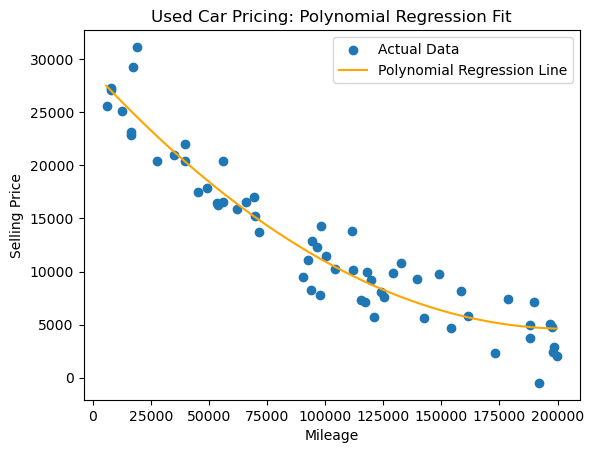

In [28]:
plt.scatter(X_test['mileage'], y_test, label='Actual Data')
plt.plot(x_range, y_range_pred, color='orange', label='Polynomial Regression Line')
plt.title('Used Car Pricing: Polynomial Regression Fit')
plt.xlabel('Mileage')
plt.ylabel('Selling Price')
plt.legend()
plt.show()